# Практика. Тензорное исчисление и автоматическое дифференцирование
---

## Цели работы
1. Научиться создавать и преобразовывать тензоры в PyTorch.
2. Понять механизм broadcasting и выполнять базовые линейно-алгебраические операции.
3. Вычислить градиент простой функции аналитически и сравнить с результатом `autograd`.
4. Исследовать вычислительный граф на примере более сложной функции.

---

## Повторение (на пальцах 🖐️)

- **Тензор** — это просто многомерный массив. Скаляр (0D), вектор (1D), матрица (2D), кубик (3D) и дальше — сколько угодно измерений.
- **Broadcasting** — умное растягивание меньшего тензора под размер большего при выполнении операций (как когда вы на вечеринке растягиваете историю, чтобы её слушали все).
- **Градиент** — вектор частных производных. Показывает направление наискорейшего роста функции. В машинном обучении мы идём **против** градиента, чтобы уменьшить ошибку.
- **Autograd** — встроенный в PyTorch механизм автоматического дифференцирования. Он строит вычислительный граф и по команде `.backward()` раскручивает его в обратную сторону, заполняя градиенты.

Всё вспомнили? Поехали!

## Задание 1. Основы тензорных операций

**Цель:** освоиться с созданием, индексацией, broadcasting и линейной алгеброй в PyTorch.

Импортируйте PyTorch (и NumPy, если потребуется) и выполните следующие пункты. Пишите код в ячейках ниже.

1. Создайте:
   - скаляр со значением 3.14;
   - вектор из чисел от 0 до 99;
   - матрицу 3×3, заполненную единицами;
   - тензор размера 2×3×4, заполненный случайными числами из стандартного нормального распределения (используйте `torch.randn`).
2. Создайте две случайные матрицы 5×5 и сложите их поэлементно.
3. Создайте матрицу 3×4 и вектор длины 4. Выполните матричное умножение (используйте `@` или `torch.mm`). Что получилось? Какой размер у результата?
4. Создайте вектор `v = torch.tensor([1, 2, 3])` и матрицу `m = torch.tensor([[[10, 20, 30], [40, 50, 60]],[[10, 20, 30], [40, 50, 60]]])`. Сложите их (`v + m`). Объясните, как сработал broadcasting.
5. Создайте тензор формы (1, 24). Измените его форму на (3, 8) с помощью `.view()`. Что произойдёт, если вы попытаетесь изменить на (2, 13)? Проверьте и зафиксируйте ошибку.

*Подсказка:* размерности можно проверять через `.shape`.

**Выводы по заданию 1:** (напишите в Markdown-ячейке после кода)

In [1]:
# Ваш код для задания 1
import torch

# 1. Создание тензоров
scalar = torch.tensor(3.14)
vector = torch.tensor([list(range(10))])
matrix_ones = torch.ones(3, 3)
tensor_randn = torch.randn(2, 3, 4)

print(f"Скаляр: {scalar}, размер: {scalar.shape}")
print(f"Вектор: {vector}, размер: {vector.shape}")
print(f"Матрица:\n {matrix_ones}, размер: {matrix_ones.shape}")
print(f"Трехмерный тензор:\n {tensor_randn}, размер: {tensor_randn.shape}\n")

# 2. Случайные матрицы и сложение
A = torch.randn(5,5)
B = torch.randn(5,5)
C = A+B

print(f"Сложение матриц:\n {C}, размер: {C.shape}\n")

# 3. Матричное умножение
M = torch.randn(3,4)
v = torch.randn(4)
result = M@v

print(f"Умножение матриц:\n {result}, размер: {result.shape}\n")

# 4. Broadcasting
v = torch.tensor([1,2,3])
m = torch.tensor([[10,20,30],[40,50,60]])
sum_bc = v+m

print(f"Broadcasting:\n {sum_bc}, размер: {sum_bc.shape}\n")

# 5. Изменение формы
x = torch.randn(1,24)
x_reshaped = x.view(3, 8)
# print(x_reshaped.shape)
# Попробуйте x.view(2,13)

print(f"Изменение формы:\n {x_reshaped}, размер: {x_reshaped.shape}\n")

Скаляр: 3.140000104904175, размер: torch.Size([])
Вектор: tensor([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]), размер: torch.Size([1, 10])
Матрица:
 tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]), размер: torch.Size([3, 3])
Трехмерный тензор:
 tensor([[[ 2.0413,  0.8390,  0.3976, -2.2039],
         [-0.0306, -0.8176,  1.1381, -0.7747],
         [-0.8964,  0.9136,  1.3035,  0.6997]],

        [[-0.9801, -1.3130,  1.3444, -1.5958],
         [ 0.0297,  1.5503, -0.0075,  0.8172],
         [-0.1713,  0.3838, -0.7278, -0.6726]]]), размер: torch.Size([2, 3, 4])

Сложение матриц:
 tensor([[ 0.3940,  0.8986, -1.8921,  0.5073, -1.4961],
        [ 0.2260, -0.5551,  1.7284,  0.8784, -0.3772],
        [-0.6235,  0.8974, -1.9702,  2.2633, -0.4845],
        [ 1.6033, -0.0582, -0.0127, -0.0287, -0.8088],
        [ 0.9570,  0.2935,  1.2359, -0.1872,  0.6687]]), размер: torch.Size([5, 5])

Умножение матриц:
 tensor([-1.7898, -0.4069, -2.6017]), размер: torch.Size([3])

Broadcasting:
 tensor([[1

### Выводы по заданию 1
Все операции понятны. Ошибка появилась при попытке изменить форму тензора с (1,24) на (2,13), т.к. общее кол-во элементов стало бы различным (24 != 26). Broadcasting при попытке сложения тензоров различных размерностей растянул первый до размера второго (видимо так: [1, 2, 3] -> [[1, 2, 3], [1, 2, 3]]).

## Задание 2. Ручной расчёт градиента и проверка autograd

**Цель:** убедиться, что autograd не врёт, и заодно вспомнить частные производные.

Рассмотрим функцию двух переменных (сразу смотрите функцию из бонусного варианта):
$$
f(x, y) = x^2 y + y^3
$$

1. Аналитически найдите частные производные и вычислите градиент в точке $x = 2, y = 3$. Запишите ответы (можно прямо в Markdown).
2. Создайте тензоры `x` и `y` с `requires_grad=True`, инициализировав их значениями 2 и 3.
3. Вычислите `f` и вызовите `backward()`.
4. Распечатайте `x.grad` и `y.grad`. Сравните с аналитическим расчётом.
5. **Бонус:** измените функцию, например, добавьте синус: $f = x^2 y + \sin(y)$. Повторите вычисления аналитически и через autograd.

*Подсказка:* аналитически: $\partial f/\partial x = 2xy$, $\partial f/\partial y = x^2 + 3y^2$. При (2,3): (12, 4+27=31).

In [2]:
import math

# Ваш код для задания 2
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

f = x*x*y + math.sin(y)
f.backward()

print("Градиент по x:", x.grad)
print("Градиент по y:", y.grad)

Градиент по x: tensor(12.)
Градиент по y: tensor(4.)


/tmp/ipykernel_959/3136965858.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f = x*x*y + math.sin(y)


### Выводы по заданию 2
Значения совпали.

## Задание 3. Исследование вычислительного графа

**Цель:** научиться отслеживать промежуточные узлы графа и понимать, откуда берутся градиенты.

Дана функция:
$$
L = (\mathbf{a} \cdot \mathbf{b} + c)^2
$$
где $\mathbf{a}, \mathbf{b}$ — векторы длины 3, $c$ — скаляр, а $\cdot$ b — скалярное произведение (можно использовать `torch.dot`).

1. Задайте конкретные значения: `a = torch.tensor([1., 2., 3.], requires_grad=True)`, `b = torch.tensor([4., 5., 6.], requires_grad=True)`, `c = torch.tensor([7.], requires_grad=True)`.
2. Вычислите `L`.
3. Вызовите `backward()` и выведите градиенты по `a`, `b`, `c`.
4. Попробуйте объяснить, почему градиент по `a` именно такой. Для этого можно:
   - Вспомнить, что скалярное произведение — это сумма поэлементных произведений.
   - Записать формулу явно и взять производную по каждому компоненту.
5. (Бонус) Выведите значение промежуточного узла: `s = torch.dot(a, b) + c` и его градиент (можно получить, если сохранить его и вызвать ` s.retain_grad()  s.backward()`, но аккуратно с повторным вызовом).

**Важно:** перед повторным вызовом backward нужно обнулить градиенты, иначе они накопятся. Используйте `.zero_()`.

In [3]:
# Ваш код для задания 3 (без s)
a = torch.tensor([1.,2.,3.], requires_grad=True)
b = torch.tensor([4.,5.,6.], requires_grad=True)
c = torch.tensor([7.], requires_grad=True)

L = (torch.dot(a, b) + c) ** 2
L.backward()

print("grad a:", a.grad)
print("grad b:", b.grad)
print("grad c:", c.grad)

grad a: tensor([312., 390., 468.])
grad b: tensor([ 78., 156., 234.])
grad c: tensor([78.])


In [4]:
# Ваш код для задания 3
a.grad.zero_(); b.grad.zero_(); c.grad.zero_()

s = torch.dot(a, b) + c
L = s ** 2
L.backward()

print("grad a:", a.grad)
print("grad b:", b.grad)
print("grad c:", c.grad)

grad a: tensor([312., 390., 468.])
grad b: tensor([ 78., 156., 234.])
grad c: tensor([78.])


### Выводы по заданию 3
В не зависимости от использования промежуточной функции s значения частных производных не изменились, просто была другая структура расчета.

## Задание 4. Линейная регрессия с autograd

**Цель:** применить autograd для обучения простой модели.

Сгенерируйте данные:
$$y_{\text{true}} = -5 x + 12 + \text{шум}$$
для 200 точек x от -10 до 10.

Инициализируйте случайные параметры `w` и `b` с `requires_grad=True`. Напишите цикл обучения на 100 эпох:
- оценка целевой функции `y_pred = w * x + b`;
- функция потерь: RMSE (`((y_pred - y_true)**2).mean()`) (добавить корень);
- `loss.backward()`;
- обновление весов вручную (без оптимизатора): `w.data -= lr * w.grad`, `b.data -= lr * b.grad` (используйте `.data` или блок `torch.no_grad()`);
- обнуление градиентов.

Выведите итоговые параметры и постройте
1. График изменения loss с увеличением эпох;
2. Линейные графики исходной и полученной функций;
3. График самой функции loss и движение поиска минимума по ней.

*Подсказка:* не забудьте обнулять градиенты после каждого шага.

Это задание повторяет пример из лекции — попробуйте выполнить его без подглядывания, а потом сверьтесь.

Результат: w = -4.258, b = 1.604


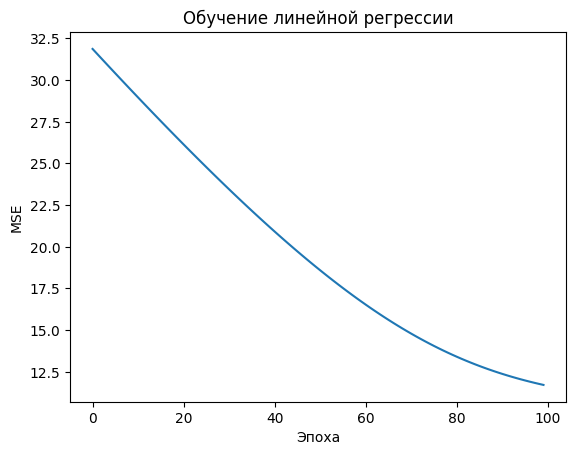

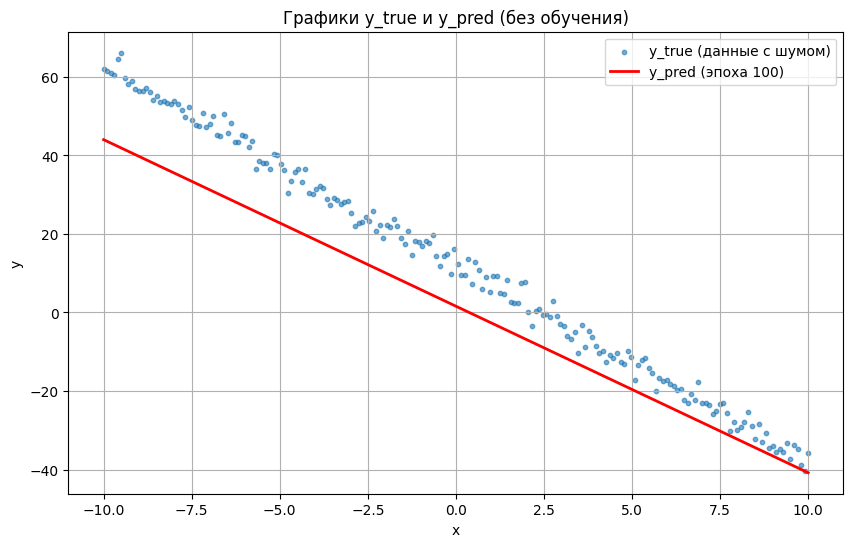

In [22]:
# Ваш код для задания 4
import matplotlib.pyplot as plt

# Генерация данных
x_true = torch.linspace(-10, 10, 200)
y_true = -5 * x_true + 12 + torch.randn_like(x_true) * 2.0

# Ручной ввод параметров w и b
w_value = 0.1
b_value = 1.

# Инициализация параметров с requires_grad=False (так как обучение не требуется)
w = torch.tensor([w_value], requires_grad=True)
b = torch.tensor([b_value], requires_grad=True)

lr = 0.01
loss_history = []

for epoch in range(100):
    # Прямой проход
    y_pred = w * x_true + b
    loss = ((y_pred-y_true)**2).mean().sqrt()
    loss_history.append(loss.item())

    # Обратный проход
    loss.backward()

    # Обновление весов
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Обнуление градиентов
    w.grad.zero_()
    b.grad.zero_()




print(f"Результат: w = {w.item():.3f}, b = {b.item():.3f}")

plt.plot(loss_history)
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.title("Обучение линейной регрессии")
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(x_true.numpy(), y_true.numpy(), label='y_true (данные с шумом)', alpha=0.6, s=10)
plt.plot(x_true.detach().numpy(), y_pred.detach().numpy(), label=f'y_pred (эпоха {epoch+1})', color='red', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Графики y_true и y_pred (без обучения)')
plt.legend()
plt.grid(True)
plt.show()

Результат: w = -4.983, b = 11.966


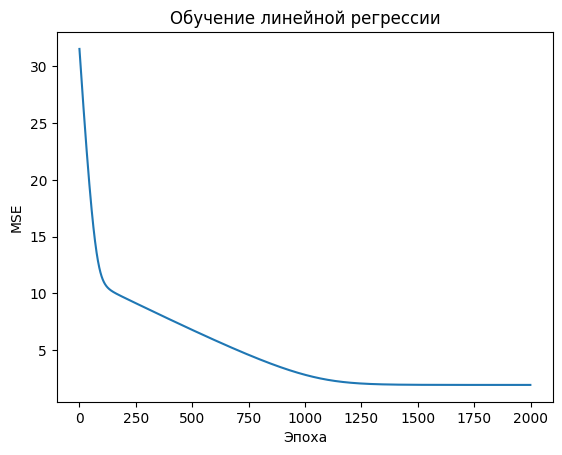

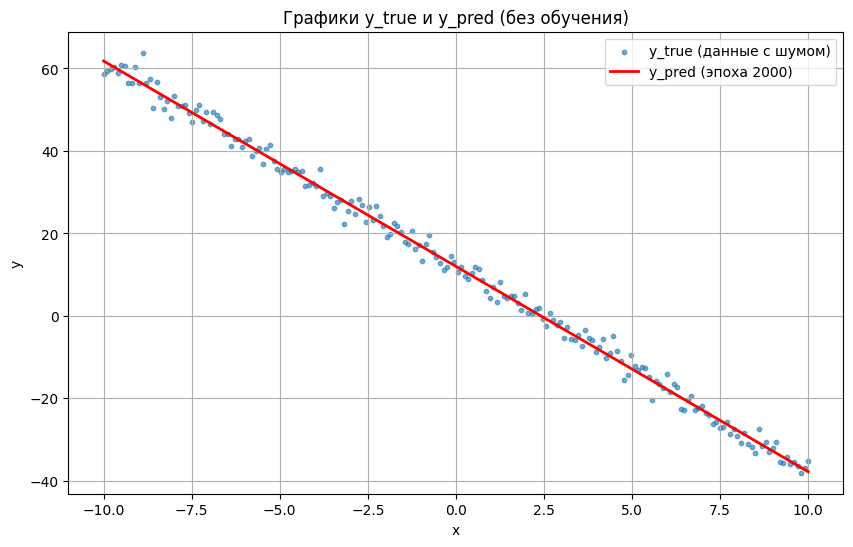

In [24]:
# Ваш код для задания 4
import matplotlib.pyplot as plt

# Генерация данных
x_true = torch.linspace(-10, 10, 200)
y_true = -5 * x_true + 12 + torch.randn_like(x_true) * 2.0

# Ручной ввод параметров w и b
w_value = 0.1
b_value = 1.

# Инициализация параметров с requires_grad=False (так как обучение не требуется)
w = torch.tensor([w_value], requires_grad=True)
b = torch.tensor([b_value], requires_grad=True)

lr = 0.01
loss_history = []

for epoch in range(2000):
    # Прямой проход
    y_pred = w * x_true + b
    loss = ((y_pred-y_true)**2).mean().sqrt()
    loss_history.append(loss.item())

    # Обратный проход
    loss.backward()

    # Обновление весов
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Обнуление градиентов
    w.grad.zero_()
    b.grad.zero_()




print(f"Результат: w = {w.item():.3f}, b = {b.item():.3f}")

plt.plot(loss_history)
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.title("Обучение линейной регрессии")
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(x_true.numpy(), y_true.numpy(), label='y_true (данные с шумом)', alpha=0.6, s=10)
plt.plot(x_true.detach().numpy(), y_pred.detach().numpy(), label=f'y_pred (эпоха {epoch+1})', color='red', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Графики y_true и y_pred (без обучения)')
plt.legend()
plt.grid(True)
plt.show()

### Выводы по заданию 4
В первом примере используется 100 эпох. Модель обучилась плохо, функция потерь не успела достигнуть глобального минимума. Построенная прямая плохо проходит по исходным данным.

На втором примере 2000 эпох, этого хватает для достаточной минимизации функции потерь. Также видно, что построенная прямая хорошо проходит по исходным данным.

## Заключение

Поздравляю, вы пережили первое практическое занятие! Теперь вы умеете:
- создавать тензоры любой размерности;
- использовать broadcasting;
- считать градиенты вручную и доверять autograd;
- строить простые вычислительные графы.

Эти навыки пригодятся уже на следующем занятии, когда мы будем визуализировать градиентный спуск. Если остались вопросы — не стесняйтесь задавать (и да, чат с одногруппниками тоже работает).

**Сдавайте выполненную работу в виде этого блокнота с заполненными ячейками и выводами.**

Успехов!